In [4]:
import pickle
import numpy as np
from pathlib import Path
import xgboost as xgb
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# =================================================================
# 1. LOAD THE CONSOLIDATED PICKLE DATASET
# =================================================================
data_path = Path("../raw_data/final_curated_imaging_clinical_data.pkl")
if not data_path.exists():
    raise FileNotFoundError(f"Could not find the dataset at {data_path}. Make sure the previous cell ran successfully!")

with open(data_path, 'rb') as f:
    final_fc_results = pickle.load(f)

print("Successfully loaded curated dataset into memory.")

# =================================================================
# 2. FEATURE EXTRACTION ENGINE (FC & FS ONLY)
# =================================================================
def get_matrix_features(matrix):
    """
    Uniformly extracts row and column metrics from any 2D connectivity matrix.
    """
    # Clean NaNs and zero the diagonal to prevent self-loops from skewing stats
    mat = np.nan_to_num(matrix)
    mat_abs = np.abs(mat)
    np.fill_diagonal(mat_abs, 0)
    
    # Row metrics (Out-degree / Sender properties)
    row_mean = np.mean(mat_abs, axis=1)
    row_std = np.std(mat_abs, axis=1)
    row_max = np.max(mat_abs, axis=1)
    row_median = np.median(mat_abs, axis=1)
    
    # Column metrics (In-degree / Receiver properties)
    col_mean = np.mean(mat_abs, axis=0)
    col_std = np.std(mat_abs, axis=0)
    col_max = np.max(mat_abs, axis=0)
    col_median = np.median(mat_abs, axis=0)
    
    # Network Asymmetry (Out-strength minus In-strength)
    asymmetry = row_mean - col_mean
    
    # Returns 9 metric arrays (each a 100-element vector for 100 ROIs)
    return [
        row_mean, row_std, row_max, row_median,
        col_mean, col_std, col_max, col_median, 
        asymmetry
    ]

# =================================================================
# 3. BUILD TABULAR MODEL INPUTS (X, y)
# =================================================================
X_list = []
y_list = []

# Map Diagnostic Labels: AP = 0, NAP = 1
group_mapping = {"AP": 0, "NAP": 1}

for class_label, diagnostic_marker in group_mapping.items():
    # Gather subject list from this group
    subject_names = list(final_fc_results[class_label]["FC"].keys())
    print(f"Processing group: {class_label} ({len(subject_names)} subjects)...")
    
    for sub_name in subject_names:
        # Pull raw saved matrices from pickle
        fc_matrix = final_fc_results[class_label]["FC"][sub_name]
        fs_matrix = final_fc_results[class_label]["FS"][sub_name] # Shifted/Lagged matrix (tau=1)
        
        # Calculate localized network metrics (900 features per matrix)
        fc_features = get_matrix_features(fc_matrix)
        fs_features = get_matrix_features(fs_matrix)
        
        # Combine the structural characteristics
        sub_features = np.concatenate([*fc_features, *fs_features])
        
        # Append diagnostic marker code (0 or 1) as a structural feature
        sub_features = np.append(sub_features, diagnostic_marker)
        
        # Pull PANSS score (convert None to np.nan so it can be filtered cleanly)
        panss_score = final_fc_results[class_label]["PANSS"][sub_name]
        y_val = float(panss_score) if panss_score is not None else np.nan
        
        X_list.append(sub_features)
        y_list.append(y_val)

X = np.array(X_list)
y = np.array(y_list)

# --- UPDATED FILTER: Strip out rows where clinical PANSS outcomes are missing, unrecorded, OR 0 ---
valid_mask = (~np.isnan(y)) & (y != 0)
X = X[valid_mask]
y = y[valid_mask]

print(f"\nFinal Tabular Dataset Shape:")
print(f"  -> Features (X): {X.shape} ({X.shape[1]} metrics per subject)")
print(f"  -> Labels (y):   {y.shape} valid non-zero PANSS scores available")

# =================================================================
# 4. LEAVE-ONE-OUT CROSS-VALIDATION PIPELINE
# =================================================================
print("\n" + "="*50)
print("RUNNING LEAVE-ONE-OUT CROSS-VALIDATION (LOOCV)")
print("="*50)

y_true_all = []
y_pred_all = []

loo = LeaveOneOut()

# Loop through iterations where N-1 items train the system and 1 tests it
for train_index, test_index in loo.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    
    # Regularized tree configuration for wide feature distributions
    xgb_model = xgb.XGBRegressor(
        n_estimators=180,
        max_depth=3,
        learning_rate=0.04,
        subsample=0.8,
        colsample_bytree=0.3,
        reg_alpha=0.8,
        reg_lambda=1.5,
        random_state=42,
        n_jobs=-1           # Parallel processing engine usage
    )
    
    # Fit model to training block
    xgb_model.fit(X_train, y_train)
    
    # Evaluate performance on test boundary item
    pred = xgb_model.predict(X_test)
    
    y_true_all.append(y_test[0])
    y_pred_all.append(pred[0])

# Convert evaluation vectors to NumPy arrays
y_true_all = np.array(y_true_all)
y_pred_all = np.array(y_pred_all)

# =================================================================
# 5. METRIC REPORTING
# =================================================================
print("\n--- Final Performance Summary ---")
print(f"LOOCV RMSE:      {np.sqrt(mean_squared_error(y_true_all, y_pred_all)):.4f}")
print(f"LOOCV MAE:       {mean_absolute_error(y_true_all, y_pred_all):.4f}")
print(f"LOOCV R² Score:  {r2_score(y_true_all, y_pred_all):.4f}")

Successfully loaded curated dataset into memory.
Processing group: AP (166 subjects)...
Processing group: NAP (166 subjects)...

Final Tabular Dataset Shape:
  -> Features (X): (203, 1801) (1801 metrics per subject)
  -> Labels (y):   (203,) valid non-zero PANSS scores available

RUNNING LEAVE-ONE-OUT CROSS-VALIDATION (LOOCV)

--- Final Performance Summary ---
LOOCV RMSE:      10.3883
LOOCV MAE:       8.6141
LOOCV R² Score:  0.0703


In [3]:
y_true_all

array([46., 38., 49., 44., 53., 67., 46., 61., 51., 59., 50., 76., 54.,
       54., 60., 52., 70., 49., 71., 61., 60., 64., 57., 62., 62., 58.,
       60., 44., 52., 61., 57., 38., 62., 54., 54., 66., 65., 46., 34.,
       40., 45., 44., 51., 43., 52., 62., 49., 32., 30., 58., 49., 36.,
       32., 65., 53., 36., 50., 47., 64., 46., 57., 59., 55., 46., 57.,
       78.,  0., 54., 40., 43., 48., 64., 36., 54., 53., 54., 41.,  0.,
       35., 41., 53., 42.,  0.,  0., 42., 46., 70., 37., 37., 36., 37.,
       47., 40., 31., 40., 39., 39., 35., 37., 50.,  0.,  0., 35., 56.,
       43., 48., 42., 46., 38., 49., 44., 53., 67., 46., 61., 51., 59.,
       43., 50., 76., 54., 54., 60., 52., 70., 49., 71., 61., 60., 64.,
       57., 62., 62., 58., 60., 44., 52., 61., 57., 38., 62., 54., 54.,
       66., 65., 46., 34., 40., 45., 44., 51., 43., 52., 62., 49., 32.,
       30., 58., 49., 36., 32., 65., 53., 36., 50., 47., 64., 46., 57.,
       59., 55., 46., 57., 78.,  0., 54., 40., 43., 48., 64., 36

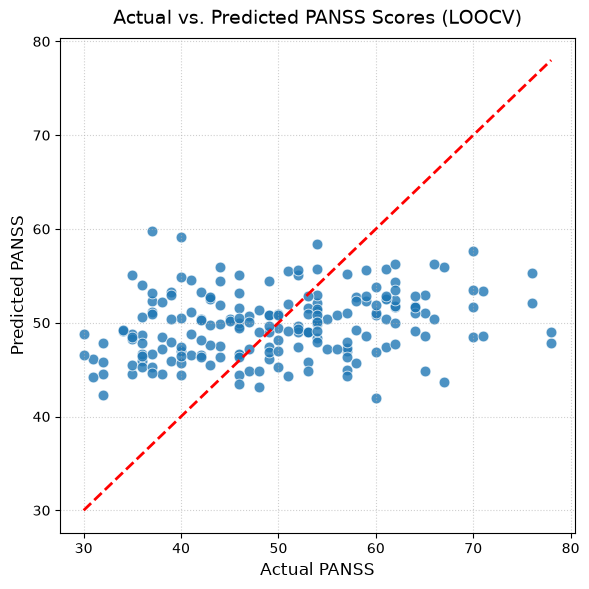

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the figure space for a single plot
plt.figure(figsize=(6, 6))

# Plot Actual vs Predicted scores using the aggregated LOOCV arrays
sns.scatterplot(x=y_true_all, y=y_pred_all, color='#1f77b4', s=60, alpha=0.8)

# Add the identity line representing perfect predictions
min_val = min(min(y_true_all), min(y_pred_all))
max_val = max(max(y_true_all), max(y_pred_all))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)

# Format the plot aesthetics
plt.title('Actual vs. Predicted PANSS Scores (LOOCV)', fontsize=14, pad=10)
plt.xlabel('Actual PANSS', fontsize=12)
plt.ylabel('Predicted PANSS', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()